# 05 – Calibration and interpretability

1. Can post-hoc calibration (Platt / isotonic) improve XGBoost's PDs?
2. Which drivers explain default risk, and do XGBoost (SHAP) and the logistic regression agree?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss
from scipy.stats import ks_2samp
from xgboost import XGBClassifier

In [2]:
train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

target = "SeriousDlqin2yrs"
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

print(X_train.shape, X_test.shape, len(y_train), len(y_test))

(119999, 14) (30000, 14) 119999 30000


## 1. Post-hoc calibration
Calibration is learned with 5-fold cross-validation inside the training set, so the test set is never used.

In [3]:
def evaluar(nombre, y_real, pd_estimada):
    """Discrimination and calibration metrics for a PD model."""
    auc = roc_auc_score(y_real, pd_estimada)
    ks = ks_2samp(pd_estimada[y_real == 1], pd_estimada[y_real == 0]).statistic
    return {
        "Model": nombre,
        "AUC": round(auc, 4),
        "Gini": round(2 * auc - 1, 4),
        "KS": round(ks, 4),
        "Brier": round(brier_score_loss(y_real, pd_estimada), 4),
        "Avg PD": round(pd_estimada.mean(), 4),
    }

In [4]:
def nuevo_xgb():
    """XGBoost with the same parameters as notebook 04."""
    return XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    )

modelos = {
    "XGBoost (raw)": nuevo_xgb(),
    "XGBoost + Platt": CalibratedClassifierCV(estimator=nuevo_xgb(), method="sigmoid", cv=5),
    "XGBoost + Isotonic": CalibratedClassifierCV(estimator=nuevo_xgb(), method="isotonic", cv=5),
}

pds = {}
resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pds[nombre] = modelo.predict_proba(X_test)[:, 1]
    resultados.append(evaluar(nombre, y_test, pds[nombre]))
    print(nombre, "listo")

pd.DataFrame(resultados)

XGBoost (raw) listo
XGBoost + Platt listo
XGBoost + Isotonic listo


,Model,AUC,Gini,KS,Brier,Avg PD
0,XGBoost (raw),0.8695,0.7389,0.5847,0.0487,0.0669
1,XGBoost + Platt,0.8695,0.7389,0.5849,0.0504,0.0672
2,XGBoost + Isotonic,0.8695,0.7390,0.5857,0.0487,0.0669


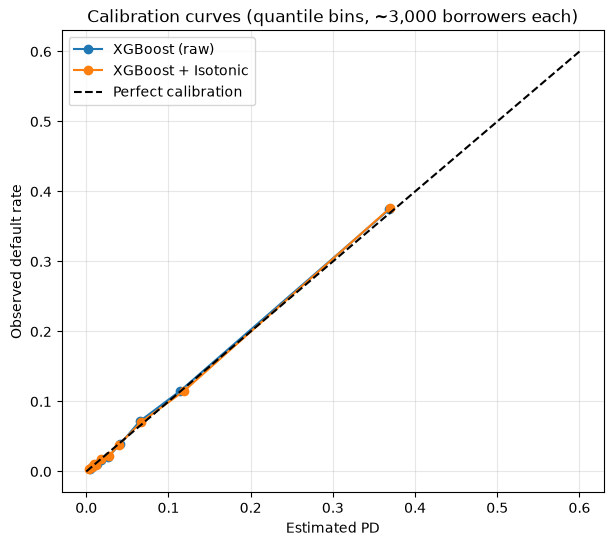

In [5]:
plt.figure(figsize=(7, 6))

for nombre in ["XGBoost (raw)", "XGBoost + Isotonic"]:
    frac_real, prob_media = calibration_curve(y_test, pds[nombre], n_bins=10, strategy="quantile")
    plt.plot(prob_media, frac_real, marker="o", label=nombre)

plt.plot([0, 0.6], [0, 0.6], "k--", label="Perfect calibration")
plt.xlabel("Estimated PD")
plt.ylabel("Observed default rate")
plt.title("Calibration curves (quantile bins, ~3,000 borrowers each)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/calibration_quantile.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Interpretability: SHAP values (XGBoost)

In [7]:
%pip install shap

  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 15.8 MB/s  0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


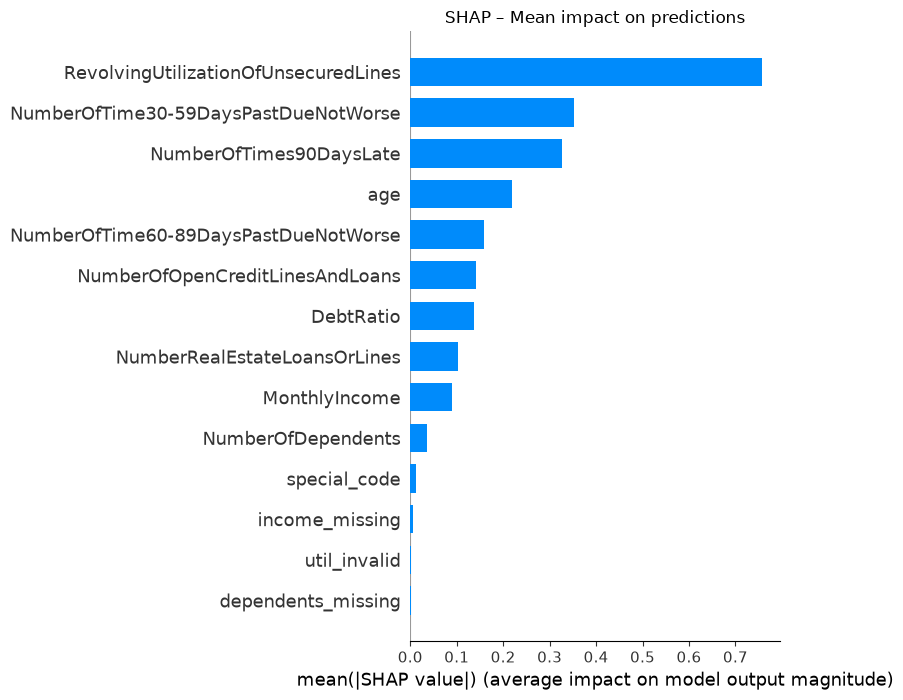

In [8]:
import shap

xgb = modelos["XGBoost (raw)"]
muestra = X_test.sample(5000, random_state=42)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(muestra)

shap.summary_plot(shap_values, muestra, plot_type="bar", show=False)
plt.title("SHAP – Mean impact on predictions")
plt.tight_layout()
plt.savefig("../reports/figures/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

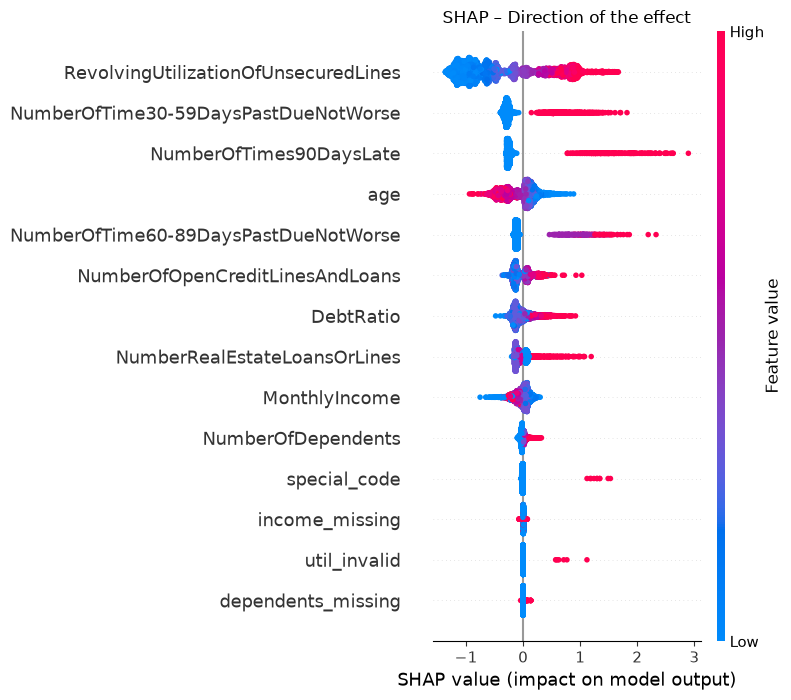

In [9]:
shap.summary_plot(shap_values, muestra, show=False)
plt.title("SHAP – Direction of the effect")
plt.tight_layout()
plt.savefig("../reports/figures/shap_direction.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

### 1. Post-hoc calibration is not needed

| Model | AUC | Brier | Avg PD |
|---|---|---|---|
| **XGBoost (raw)** | **0.8695** | **0.0487** | 6.69% |
| XGBoost + Platt | 0.8695 | 0.0504 | 6.72% |
| XGBoost + Isotonic | 0.8695 | 0.0487 | 6.69% |

*Observed default rate in the test set: 6.68%.*

- **XGBoost is already well calibrated.** Platt scaling worsens the Brier score by forcing an S-shaped correction the model does not need, and isotonic regression leaves it unchanged. AUC is identical in all cases, since recalibration does not change the ranking of borrowers.
- **The quantile calibration curve (10 bins of ~3,000 borrowers) lies on the diagonal**, including the riskiest decile (estimated PD ~37%, observed ~37.5%). The noise seen above 0.7 in notebook 04 came from equal-width bins with very few borrowers.
- **Key takeaway:** the calibration problem in the original thesis came from SMOTE, not from the model. Trained on the real class distribution, XGBoost produces PDs that can be used directly.

### 2. Both models agree on the drivers of risk

- **The top 5 drivers are the same in XGBoost (SHAP) and the logistic regression (coefficients):** revolving utilization, the three past-due variables and age. Two very different models reaching the same drivers supports the robustness of the results.
- **All main effects make economic sense:** higher utilization and more past-due events increase risk; older borrowers are less risky.
- **XGBoost recovers the correct sign of `DebtRatio`** (higher debt ratio, higher risk), which the logistic regression estimated as negative. This confirms the issue was a limitation of the linear model, not of the data.
- **Rare flags have a large individual effect:** `special_code` and `util_invalid` rank low on average because few borrowers have them, but raise the prediction substantially for those who do.
- **Observation:** some low-income borrowers show a negative SHAP contribution, which may reflect an interaction with `DebtRatio` (already defined relative to income). To be reviewed.